In [37]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

print("Everything works!")

Everything works!


In [38]:
def read_conll(filepath):
    sentences = []
    tags = []
    current_sentence = []
    current_tags = []
# Read Cell format file and convert it into a list of sentences and corresponding tags
    with open(filepath, "r", encoding="utf-8") as f:

        for line in f:

            line = line.strip()

            # sentence ended
            if line == "": # if reach to the end of a sentence store the current sentence and tags into the list of sentences and tags
                if current_sentence:
                    sentences.append(current_sentence)
                    tags.append(current_tags)

                    current_sentence = []
                    current_tags = []
                continue

            cols = line.split("\t") # divide the line into columns based on tab separation and store as list

            word = cols[1] # get the word from
            cpos = cols[3] # get the coarse POS tag from
            fpos = cols[4] # get the fine POS tag from

            joint_tag = f"{cpos}-{fpos}" # combine the coarse and fine POS tags into a single tag

            current_sentence.append(word)
            current_tags.append(joint_tag)

    return sentences, tags

In [39]:
train_sentences, train_tags = read_conll( # train sentences and tags from the training dataset
    "en-universal-train.conll"
)

dev_sentences, dev_tags = read_conll(
    "en-universal-dev.conll"
)

In [40]:
print(train_sentences[0])
print()
print(train_tags[0])

['In', 'an', 'Oct.', '19', 'review', 'of', '``', 'The', 'Misanthrope', "''", 'at', 'Chicago', "'s", 'Goodman', 'Theatre', '(', '``', 'Revitalized', 'Classics', 'Take', 'the', 'Stage', 'in', 'Windy', 'City', ',', "''", 'Leisure', '&', 'Arts', ')', ',', 'the', 'role', 'of', 'Celimene', ',', 'played', 'by', 'Kim', 'Cattrall', ',', 'was', 'mistakenly', 'attributed', 'to', 'Christina', 'Haag', '.']

['ADP-IN', 'DET-DT', 'NOUN-NNP', 'NUM-CD', 'NOUN-NN', 'ADP-IN', '.-``', 'DET-DT', 'NOUN-NN', ".-''", 'ADP-IN', 'NOUN-NNP', 'PRT-POS', 'NOUN-NNP', 'NOUN-NNP', '.-(', '.-``', 'VERB-VBN', 'NOUN-NNS', 'VERB-VBP', 'DET-DT', 'NOUN-NN', 'ADP-IN', 'NOUN-NNP', 'NOUN-NNP', '.-,', ".-''", 'NOUN-NN', 'CONJ-CC', 'NOUN-NNS', '.-)', '.-,', 'DET-DT', 'NOUN-NN', 'ADP-IN', 'NOUN-NNP', '.-,', 'VERB-VBN', 'ADP-IN', 'NOUN-NNP', 'NOUN-NNP', '.-,', 'VERB-VBD', 'ADV-RB', 'VERB-VBN', 'ADP-IN', 'NOUN-NNP', 'NOUN-NNP', '.-.']


In [6]:
num_sentences = len(train_sentences)

num_words = sum(
    len(sentence)
    for sentence in train_sentences
)

avg_length = np.mean(
    [len(sentence)
     for sentence in train_sentences]
)

print("Number of sentences:", num_sentences)
print("Number of words:", num_words)
print("Average sentence length:", avg_length)

Number of sentences: 37839
Number of words: 902885
Average sentence length: 23.861227833716537


In [7]:
lengths = [
    len(sentence)
    for sentence in train_sentences
]
# extract the lengths of all sentences in the training dataset and store them in a list
print("Longest sentence:", max(lengths))
print("Shortest sentence:", min(lengths))

Longest sentence: 141
Shortest sentence: 1


In [8]:
all_tags = []
# compile a list of all tags in the training dataset by iterating through each sentence's tags and extending the all_tags list with them 
# compute the frequency of each tag in the training dataset using the Counter class from the collections module
for sentence_tags in train_tags:
    all_tags.extend(sentence_tags)

tag_counter = Counter(all_tags)

print("Number of unique tags:",
      len(tag_counter))

print()

print("Top 20 tags:")

for tag, count in tag_counter.most_common(20):
    print(tag, count)

Number of unique tags: 45

Top 20 tags:
NOUN-NN 126173
ADP-IN 102515
NOUN-NNP 87033
DET-DT 77719
ADJ-JJ 58227
NOUN-NNS 56900
.-, 46317
.-. 37505
NUM-CD 34775
ADV-RB 29381
VERB-VBD 28454
VERB-VB 25146
CONJ-CC 22734
VERB-VBZ 20560
VERB-VBN 19068
PRON-PRP 16577
VERB-VBG 14131
PRT-TO 12417
VERB-VBP 11815
VERB-MD 9330


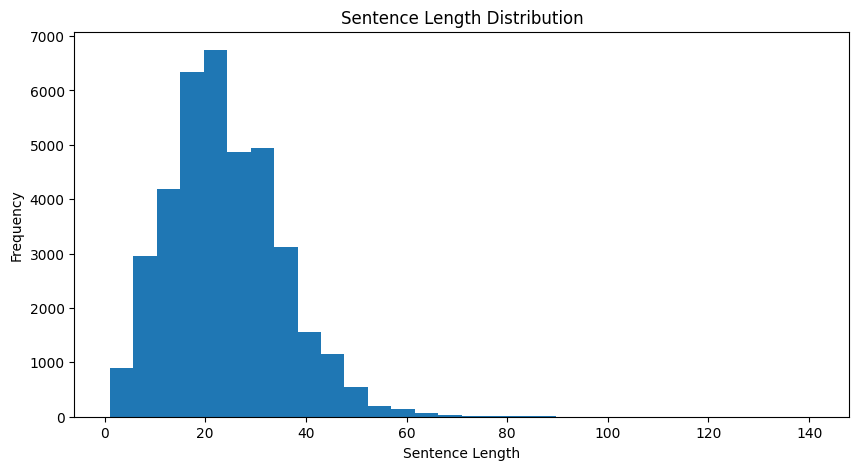

In [9]:
sentence_lengths = [
    len(sentence)
    for sentence in train_sentences
]

plt.figure(figsize=(10,5))

plt.hist(sentence_lengths,
         bins=30)

plt.title("Sentence Length Distribution")
plt.xlabel("Sentence Length")
plt.ylabel("Frequency")

plt.show()

In [10]:
word2idx = {
    "<PAD>":0, # use 0 for  short sentences
    "<UNK>":1 # use 1 for unknown words
}
# create a dictionary to map each unique word in the training dataset to a unique index, starting with special tokens for padding and unknown words
for sentence in train_sentences:

    for word in sentence:
# if word is nor already in the word2idx add it 
        if word not in word2idx:
            word2idx[word] = len(word2idx)

print("Vocabulary Size:",
      len(word2idx))

Vocabulary Size: 43359


In [11]:
tag2idx = {}
# convet the pos tags into a dictionary that maps each unique tag to a unique index
for sentence_tags in train_tags:

    for tag in sentence_tags:

        if tag not in tag2idx:
            tag2idx[tag] = len(tag2idx)

idx2tag = {
    idx:tag
    for tag, idx in tag2idx.items()
}

print("Number of Tags:",
      len(tag2idx))

Number of Tags: 45


In [12]:
def sentence_to_ids(sentence):

    return [
        word2idx.get(word,
                     word2idx["<UNK>"])
        for word in sentence
    ]

In [13]:
def tags_to_ids(tags):

    return [
        tag2idx[tag]
        for tag in tags
    ]

In [14]:
print(train_sentences[0])

print()

print(sentence_to_ids(
    train_sentences[0]
))

['In', 'an', 'Oct.', '19', 'review', 'of', '``', 'The', 'Misanthrope', "''", 'at', 'Chicago', "'s", 'Goodman', 'Theatre', '(', '``', 'Revitalized', 'Classics', 'Take', 'the', 'Stage', 'in', 'Windy', 'City', ',', "''", 'Leisure', '&', 'Arts', ')', ',', 'the', 'role', 'of', 'Celimene', ',', 'played', 'by', 'Kim', 'Cattrall', ',', 'was', 'mistakenly', 'attributed', 'to', 'Christina', 'Haag', '.']

[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 8, 18, 19, 20, 21, 22, 23, 24, 25, 26, 11, 27, 28, 29, 30, 26, 21, 31, 7, 32, 26, 33, 34, 35, 36, 26, 37, 38, 39, 40, 41, 42, 43]


In [15]:
def pad_sequences(sequences, max_len, pad_value=0):

    padded = []
# Pad each sequence to the maximum length by truncating or adding the pad_value as needed
    for seq in sequences:

        seq = seq[:max_len]

        seq = seq + [pad_value] * (max_len - len(seq))

        padded.append(seq)

    return padded

In [16]:
max_len = max(
    len(sentence)
    for sentence in train_sentences
)

print("Max Length =", max_len)

Max Length = 141


In [17]:
train_inputs = [
    sentence_to_ids(sentence)
    for sentence in train_sentences
]

dev_inputs = [
    sentence_to_ids(sentence)
    for sentence in dev_sentences
]

In [18]:
train_outputs = [
    tags_to_ids(tags)
    for tags in train_tags
]

dev_outputs = [
    tags_to_ids(tags)
    for tags in dev_tags
]

In [19]:
train_inputs = pad_sequences(
    train_inputs,
    max_len,
    word2idx["<PAD>"]
)

train_outputs = pad_sequences(
    train_outputs,
    max_len,
    0
)

dev_inputs = pad_sequences(
    dev_inputs,
    max_len,
    word2idx["<PAD>"]
)

dev_outputs = pad_sequences(
    dev_outputs,
    max_len,
    0
)

In [20]:
import torch
from torch.utils.data import Dataset

In [21]:
class POSDataset(Dataset):
#   A custom dataset class for POS tagging that inherits from the PyTorch Dataset class. It takes in a list of input sequences and their corresponding labels, and implements the __len__ and __getitem__ methods to allow for easy indexing and batching of the data.
    def __init__(self, inputs, labels):

        self.inputs = inputs
        self.labels = labels

    def __len__(self):

        return len(self.inputs)

    def __getitem__(self, idx):

        return (
            torch.tensor(self.inputs[idx],
                         dtype=torch.long),

            torch.tensor(self.labels[idx],
                         dtype=torch.long)
        )

In [22]:
from torch.utils.data import DataLoader

In [23]:
# Read the training and development datasets into custom POSDataset objects, which can be used to create DataLoader objects
train_dataset = POSDataset(
    train_inputs,
    train_outputs
)

dev_dataset = POSDataset(
    dev_inputs,
    dev_outputs
)

In [24]:
# divide the training and development datasets into batches of 32 samples each, with shuffling enabled for the training dataset to improve generalization
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=False
)

In [25]:
print("Train Sentences:",
      len(train_dataset)) # number of sentences in the training dataset

print("Dev Sentences:",
      len(dev_dataset)) # number of sentences in the development dataset (validation dataset)

print("Train Batches:",
      len(train_loader)) # number of batches in the training dataset

print("Dev Batches:",
      len(dev_loader)) # number of batches in the development dataset (validation dataset)

print("Vocabulary Size:",
      len(word2idx)) # number of unique words in the training dataset

print("Number of Tags:",
      len(tag2idx)) # number of unique part-of-speech tags in the training dataset

Train Sentences: 37839
Dev Sentences: 1992
Train Batches: 1183
Dev Batches: 63
Vocabulary Size: 43359
Number of Tags: 45


In [26]:
max_len = max(len(s) for s in train_sentences)

print("Max Length:", max_len)

Max Length: 141


In [27]:
def pad_sequences(sequences, max_len, pad_value=0):

    padded = []

    for seq in sequences:
        seq = seq[:max_len]
        seq = seq + [pad_value] * (max_len - len(seq))
        padded.append(seq)

    return padded


train_inputs = pad_sequences(train_inputs, max_len, word2idx["<PAD>"])
dev_inputs   = pad_sequences(dev_inputs, max_len, word2idx["<PAD>"])

train_outputs = pad_sequences(train_outputs, max_len, 0)
dev_outputs   = pad_sequences(dev_outputs, max_len, 0)

In [28]:
train_inputs = [sentence_to_ids(s) for s in train_sentences]
dev_inputs   = [sentence_to_ids(s) for s in dev_sentences]

In [29]:
train_outputs = [tags_to_ids(t) for t in train_tags]
dev_outputs   = [tags_to_ids(t) for t in dev_tags]

In [30]:
train_inputs = pad_sequences(train_inputs, max_len, word2idx["<PAD>"])
dev_inputs   = pad_sequences(dev_inputs, max_len, word2idx["<PAD>"])

train_outputs = pad_sequences(train_outputs, max_len, 0)
dev_outputs   = pad_sequences(dev_outputs, max_len, 0)

In [31]:
import torch
from torch.utils.data import Dataset, DataLoader

class POSDataset(Dataset):
    def __init__(self, inputs, labels):
        self.inputs = inputs
        self.labels = labels

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.inputs[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )


train_dataset = POSDataset(train_inputs, train_outputs)
dev_dataset   = POSDataset(dev_inputs, dev_outputs)

In [32]:
print(len(train_dataset))
print(len(dev_dataset))
print(len(train_loader))
print(len(dev_loader))

print(len(word2idx))
print(len(tag2idx))
print(max_len)

37839
1992
1183
63
43359
45
141


In [33]:
import torch.nn as nn

class BiLSTMTagger(nn.Module):

    def __init__(self, vocab_size, tag_size, embedding_dim=128, hidden_dim=128):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            bidirectional=True,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim * 2, tag_size)

    def forward(self, x):
        x = self.embedding(x)
        lstm_out, _ = self.lstm(x)
        logits = self.fc(lstm_out)
        return logits

In [34]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BiLSTMTagger(len(word2idx), len(tag2idx)).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [41]:
for epoch in range(5):

    model.train()
    total_loss = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        output = model(x)

        output = output.view(-1, output.shape[-1])
        y = y.view(-1)

        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

KeyboardInterrupt: 

In [ ]:
correct = 0
total = 0

with torch.no_grad():

    for x, y in dev_loader:

        output = model(x)

        preds = output.argmax(dim=-1)

        preds = preds.view(-1)
        y = y.view(-1)

        mask = y != 0   

        correct += (preds[mask] == y[mask]).sum().item()
        total += mask.sum().item()

accuracy = correct / total

print("BiLSTM Accuracy:", accuracy)

BiLSTM Accuracy: 0.9551449292706863


In [ ]:
def accuracy(preds, labels):

    correct = (preds == labels).sum().item()
    total = labels.numel()

    return correct / total

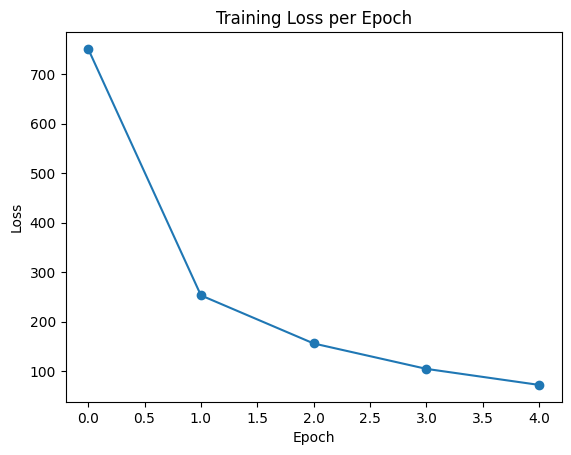

In [ ]:
losses = [750.7312, 253.3032, 156.2430, 104.9560, 72.5653]
import matplotlib.pyplot as plt

plt.plot(losses, marker='o')
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
from collections import defaultdict, Counter

word_tag_counts = defaultdict(Counter)
# count the occurrences of each word-tag pair in the training dataset and store them in a nested dictionary, where the outer dictionary maps each word to a Counter object that counts the occurrences of each tag associated with that word
for sentence, tags in zip(train_sentences, train_tags):
    for w, t in zip(sentence, tags):
        word_tag_counts[w][t] += 1

In [ ]:
word_most_freq_tag = {}
# determine the most frequent tag for each word in the training dataset by iterating through the word_tag_counts dictionary and selecting the tag with the highest count for each word, storing the results in a new dictionary called word_most_freq_tag
for word, counter in word_tag_counts.items():
    word_most_freq_tag[word] = counter.most_common(1)[0][0]

In [ ]:
all_tags = [tag for tags in train_tags for tag in tags]
# compute the common tag in the training dataset
most_common_tag = Counter(all_tags).most_common(1)[0][0]

print("Most common tag:", most_common_tag)

Most common tag: NOUN-NN


In [ ]:
def baseline_predict(sentence):
# this no ai model, it just predict the most common tag for each word in the sentence, if the word is not in the training dataset it will predict the most common tag in the training dataset
    preds = []

    for word in sentence:

        if word in word_most_freq_tag:
            preds.append(word_most_freq_tag[word])
        else:
            preds.append(most_common_tag)

    return preds

In [ ]:
def evaluate_baseline(sentences, gold_tags):

    correct = 0
    total = 0

    for sentence, true_tags in zip(sentences, gold_tags):

        pred_tags = baseline_predict(sentence)

        for p, t in zip(pred_tags, true_tags):
            if p == t:
                correct += 1
            total += 1

    accuracy = correct / total
    return accuracy

In [ ]:
baseline_acc = evaluate_baseline(dev_sentences, dev_tags)

print("Baseline Accuracy:", baseline_acc)

Baseline Accuracy: 0.9141238382209396


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

print("✅ All imports successful!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

✅ All imports successful!
PyTorch version: 2.5.1+cpu
CUDA available: False


In [ ]:
import os

print("📁 Files in current directory:")
for file in os.listdir():
    if file.endswith('.conll'):
        print(f"  ✅ {file}")
    elif file.endswith('.txt'):
        print(f"  📄 {file}")

train_file = 'en-universal-train.conll'
dev_file = 'en-universal-dev.conll'

if os.path.exists(train_file) and os.path.exists(dev_file):
    print("\n✅ Both data files found!")
else:
    print("\n❌ Missing files! Please check:")
    if not os.path.exists(train_file):
        print(f"   - {train_file} not found")
    if not os.path.exists(dev_file):
        print(f"   - {dev_file} not found")

📁 Files in current directory:
  ✅ en-universal-dev.conll
  ✅ en-universal-train.conll

✅ Both data files found!


In [ ]:
def read_conll(filepath):
    """
    Read a CoNLL file and extract sentences and tags
    """
    sentences = []
    tags = []
    
    with open(filepath, 'r', encoding='utf-8') as f:
        current_sentence = []
        current_tags = []
        
        for line in f:
            line = line.strip()
            
            # Empty line = end of sentence
            if line == '':
                if current_sentence:
                    sentences.append(current_sentence)
                    tags.append(current_tags)
                    current_sentence = []
                    current_tags = []
                continue
            
            # Split by tab
            parts = line.split('\t')
            
            if len(parts) >= 5:
                word = parts[1]          # Word
                cpos = parts[3]          # Coarse POS
                fpos = parts[4]          # Fine POS
                tag = f"{cpos}-{fpos}"   # Joint Tag
                
                current_sentence.append(word)
                current_tags.append(tag)
    
    # Add last sentence if not empty
    if current_sentence:
        sentences.append(current_sentence)
        tags.append(current_tags)
    
    return sentences, tags

# Load data
print("📖 Reading training data...")
train_sentences, train_tags = read_conll('en-universal-train.conll')

print("📖 Reading development data...")
dev_sentences, dev_tags = read_conll('en-universal-dev.conll')

print("\n" + "="*50)
print("📊 DATA STATISTICS")
print("="*50)
print(f"Train sentences: {len(train_sentences):,}")
print(f"Dev sentences:   {len(dev_sentences):,}")
print(f"\nExample sentence (first 5 words):")
print(f"  Words: {train_sentences[0][:5]}")
print(f"  Tags:  {train_tags[0][:5]}")
print("="*50)

📖 Reading training data...
📖 Reading development data...

📊 DATA STATISTICS
Train sentences: 37,840
Dev sentences:   1,992

Example sentence (first 5 words):
  Words: ['In', 'an', 'Oct.', '19', 'review']
  Tags:  ['ADP-IN', 'DET-DT', 'NOUN-NNP', 'NUM-CD', 'NOUN-NN']


📊 WORD STATISTICS
Total words: 902,902
Unique words: 43,357
Most common words: [(',', 46313), ('the', 39038), ('.', 37081), ('of', 21804), ('to', 21123), ('a', 18310), ('and', 15297), ('in', 14456), ("'s", 8849), ('for', 7595)]

📊 TAG STATISTICS
Total tags: 902,902
Unique tags: 45
Most common tags: [('NOUN-NN', 126176), ('ADP-IN', 102515), ('NOUN-NNP', 87033), ('DET-DT', 77723), ('ADJ-JJ', 58227), ('NOUN-NNS', 56900), ('.-,', 46317), ('.-.', 37506), ('NUM-CD', 34775), ('ADV-RB', 29382)]


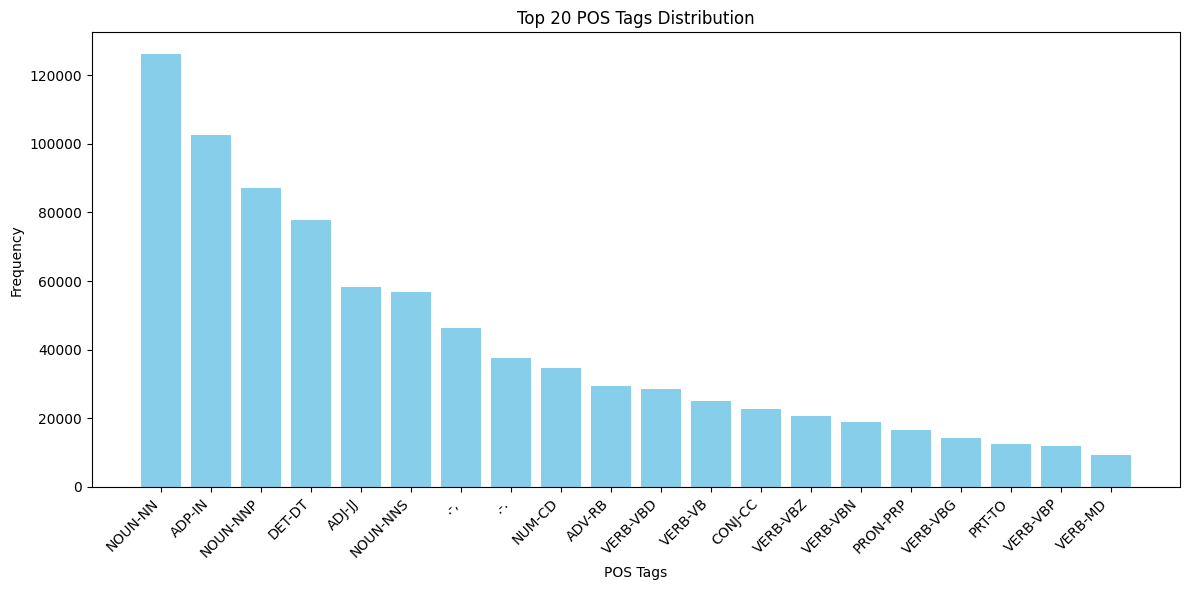


✅ Tag distribution plot saved as 'tag_distribution.png'


In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

# Calculate statistics
all_words = [word for sent in train_sentences for word in sent]
all_tags = [tag for tags in train_tags for tag in tags]

print("📊 WORD STATISTICS")
print("="*50)
print(f"Total words: {len(all_words):,}")
print(f"Unique words: {len(set(all_words)):,}")
print(f"Most common words: {Counter(all_words).most_common(10)}")

print("\n📊 TAG STATISTICS")
print("="*50)
print(f"Total tags: {len(all_tags):,}")
print(f"Unique tags: {len(set(all_tags))}")
print(f"Most common tags: {Counter(all_tags).most_common(10)}")

# Plot tag distribution
tag_counts = Counter(all_tags)
top_tags = tag_counts.most_common(20)

plt.figure(figsize=(12, 6))
tags, counts = zip(*top_tags)
plt.bar(tags, counts, color='skyblue')
plt.xlabel('POS Tags')
plt.ylabel('Frequency')
plt.title('Top 20 POS Tags Distribution')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('tag_distribution.png', dpi=150)
plt.show()

print("\n✅ Tag distribution plot saved as 'tag_distribution.png'")

In [ ]:
def build_vocab(sentences, min_freq=2):
    """
    Build vocabulary dictionary, ignoring rare words
    """
    word_counts = Counter()
    for sent in sentences:
        word_counts.update(sent)
    
    # Start with PAD and UNK
    vocab = ['<PAD>', '<UNK>']
    
    # Add words that appear more than min_freq
    for word, count in word_counts.items():
        if count >= min_freq:
            vocab.append(word)
    
    word2idx = {word: idx for idx, word in enumerate(vocab)}
    idx2word = {idx: word for word, idx in word2idx.items()}
    
    return word2idx, idx2word

def build_tag_dict(tags):
    """
    Build tag dictionary
    """
    unique_tags = set()
    for tag_seq in tags:
        unique_tags.update(tag_seq)
    
    sorted_tags = sorted(unique_tags)
    
    tag2idx = {tag: idx for idx, tag in enumerate(sorted_tags)}
    idx2tag = {idx: tag for tag, idx in tag2idx.items()}
    
    return tag2idx, idx2tag

print("🔨 Building vocabulary...")
word2idx, idx2word = build_vocab(train_sentences, min_freq=2)

print("🔨 Building tag dictionary...")
tag2idx, idx2tag = build_tag_dict(train_tags)

print("\n" + "="*50)
print("📊 DICTIONARY STATISTICS")
print("="*50)
print(f"Vocabulary size (words): {len(word2idx):,}")
print(f"Number of tags: {len(tag2idx)}")
print(f"\nFirst 10 tags:")
for i, (tag, idx) in enumerate(list(tag2idx.items())[:10]):
    print(f"  {idx}: {tag}")
print("="*50)

🔨 Building vocabulary...
🔨 Building tag dictionary...

📊 DICTIONARY STATISTICS
Vocabulary size (words): 23,099
Number of tags: 45

First 10 tags:
  0: .-#
  1: .-$
  2: .-''
  3: .-(
  4: .-)
  5: .-,
  6: .-.
  7: .-:
  8: .-``
  9: ADJ-JJ


In [ ]:
def encode_sentence(sentence, word2idx):
    """
    Convert a sentence from words to numbers
    """
    return [word2idx.get(word, word2idx['<UNK>']) for word in sentence]

def encode_tags(tag_seq, tag2idx):
    """
    Convert tag sequence to numbers
    """
    return [tag2idx[tag] for tag in tag_seq]

print("🔄 Encoding training data...")
train_inputs = [encode_sentence(sent, word2idx) for sent in train_sentences]
train_outputs = [encode_tags(tags, tag2idx) for tags in train_tags]

print("🔄 Encoding development data...")
dev_inputs = [encode_sentence(sent, word2idx) for sent in dev_sentences]
dev_outputs = [encode_tags(tags, tag2idx) for tags in dev_tags]

print("\n✅ Encoding complete!")
print(f"Example encoded sentence: {train_inputs[0][:10]}")
print(f"Example encoded tags: {train_outputs[0][:10]}")

🔄 Encoding training data...
🔄 Encoding development data...

✅ Encoding complete!
Example encoded sentence: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Example encoded tags: [12, 18, 23, 26, 22, 12, 8, 18, 22, 2]


In [ ]:
def pad_sequences(sequences, max_len, pad_value=0):
    """
    Pad sequences to the same length
    """
    padded = []
    for seq in sequences:
        if len(seq) > max_len:
            seq = seq[:max_len]  # Truncate long sequences
        else:
            seq = seq + [pad_value] * (max_len - len(seq))  # Pad short sequences
        padded.append(seq)
    return padded

# Find maximum sentence length
max_len = max(len(sent) for sent in train_sentences)
print(f"📏 Maximum sentence length: {max_len}")

# Apply padding
print("📦 Padding sequences...")
train_inputs_padded = pad_sequences(train_inputs, max_len, word2idx['<PAD>'])
train_outputs_padded = pad_sequences(train_outputs, max_len, 0)  # 0 = PAD tag

dev_inputs_padded = pad_sequences(dev_inputs, max_len, word2idx['<PAD>'])
dev_outputs_padded = pad_sequences(dev_outputs, max_len, 0)

print(f"✅ Train shape: {len(train_inputs_padded)} x {len(train_inputs_padded[0])}")
print(f"✅ Dev shape:   {len(dev_inputs_padded)} x {len(dev_inputs_padded[0])}")

📏 Maximum sentence length: 141
📦 Padding sequences...
✅ Train shape: 37840 x 141
✅ Dev shape:   1992 x 141


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class POSDataset(Dataset):
    """
    Custom Dataset for POS Tagging
    """
    def __init__(self, inputs, labels):
        self.inputs = torch.tensor(inputs, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)
    
    def __len__(self):
        return len(self.inputs)
    
    def __getitem__(self, idx):
        return self.inputs[idx], self.labels[idx]

# Create datasets
print("🏗️ Creating datasets...")
train_dataset = POSDataset(train_inputs_padded, train_outputs_padded)
dev_dataset = POSDataset(dev_inputs_padded, dev_outputs_padded)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True,
    num_workers=0
)

dev_loader = DataLoader(
    dev_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False,
    num_workers=0
)

print(f"\n✅ Train batches: {len(train_loader)}")
print(f"✅ Dev batches: {len(dev_loader)}")

# Test a sample
sample_input, sample_label = next(iter(train_loader))
print(f"\n📦 Sample batch:")
print(f"  Input shape: {sample_input.shape}")
print(f"  Label shape: {sample_label.shape}")

🏗️ Creating datasets...

✅ Train batches: 592
✅ Dev batches: 32

📦 Sample batch:
  Input shape: torch.Size([64, 141])
  Label shape: torch.Size([64, 141])


In [48]:
import torch.nn as nn

class BiLSTM_POS(nn.Module):
    """
    BiLSTM model for POS Tagging
    """
    def __init__(self, vocab_size, tag_size, embedding_dim=100, 
                 hidden_dim=128, num_layers=2, dropout=0.5):
        super().__init__()
        
        # Embedding Layer
        self.embedding = nn.Embedding(
            vocab_size, 
            embedding_dim, 
            padding_idx=0  # 0 = PAD token
        )
        
        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # Dropout for regularization
        self.dropout = nn.Dropout(dropout)
        
        # Final classification layer
        self.fc = nn.Linear(hidden_dim * 2, tag_size)  # *2 because bidirectional
    
    def forward(self, x):
        # x: (batch_size, seq_len)
        embedded = self.embedding(x)  # (batch_size, seq_len, embedding_dim)
        
        lstm_out, _ = self.lstm(embedded)  # (batch_size, seq_len, hidden_dim*2)
        
        lstm_out = self.dropout(lstm_out)
        
        output = self.fc(lstm_out)  # (batch_size, seq_len, tag_size)
        
        return output

# Create model
vocab_size = len(word2idx)
tag_size = len(tag2idx)

model = BiLSTM_POS(
    vocab_size=vocab_size,
    tag_size=tag_size,
    embedding_dim=100,
    hidden_dim=128,
    num_layers=2,
    dropout=0.5
)

print("="*50)
print("🤖 MODEL ARCHITECTURE")
print("="*50)
print(f"Vocabulary size: {vocab_size:,}")
print(f"Number of tags: {tag_size}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print("="*50)

print("\n📐 Model structure:")
print(model)

🤖 MODEL ARCHITECTURE
Vocabulary size: 43,359
Number of tags: 45
Total parameters: 4,978,249

📐 Model structure:
BiLSTM_POS(
  (embedding): Embedding(43359, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=45, bias=True)
)


In [44]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import torch.optim as optim

def evaluate(model, data_loader, device, tag2idx):
    """
    Evaluate the model
    """
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            preds = outputs.argmax(dim=-1)
            
            # Remove PAD tokens
            mask = labels != 0
            all_preds.extend(preds[mask].cpu().numpy())
            all_labels.extend(labels[mask].cpu().numpy())
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='macro', zero_division=0
    )
    
    return {
        'accuracy': accuracy,
        'macro_f1': f1,
        'precision': precision,
        'recall': recall,
        'all_preds': all_preds,
        'all_labels': all_labels
    }

def train_epoch(model, train_loader, optimizer, criterion, device):
    """
    Train for one epoch
    """
    model.train()
    total_loss = 0
    
    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        
        # Calculate loss (ignore PAD tokens)
        loss = criterion(
            outputs.view(-1, tag_size), 
            labels.view(-1)
        )
        
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        total_loss += loss.item()
    
    return total_loss / len(train_loader)

In [49]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ Using device: {device}")

model = BiLSTM_POS(
    vocab_size=vocab_size,
    tag_size=tag_size,
    embedding_dim=100,
    hidden_dim=128,
    num_layers=2,
    dropout=0.5
)
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2, verbose=True)
criterion = nn.CrossEntropyLoss(ignore_index=0)

best_dev_acc = 0
patience = 3
patience_counter = 0

train_losses = []
dev_accuracies = []
dev_f1s = []

print("\n🚀 STARTING TRAINING")
print("="*60)

for epoch in range(10):
    avg_loss = train_epoch(model, train_loader, optimizer, criterion, device)
    train_losses.append(avg_loss)
    
    dev_metrics = evaluate(model, dev_loader, device, tag2idx)
    scheduler.step(dev_metrics['accuracy'])
    dev_accuracies.append(dev_metrics['accuracy'])
    dev_f1s.append(dev_metrics['macro_f1'])
    
    print(f"\nEpoch {epoch+1}/10")
    print(f"  Train Loss: {avg_loss:.4f}")
    print(f"  Dev Accuracy: {dev_metrics['accuracy']:.4f}")
    print(f"  Dev Macro F1: {dev_metrics['macro_f1']:.4f}")
    
    if dev_metrics['accuracy'] > best_dev_acc:
        best_dev_acc = dev_metrics['accuracy']
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pt')
        print("  ✅ New best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\n⏹️ Early stopping triggered after {epoch+1} epochs")
            break

print("\n" + "="*60)
print("✅ Training complete!")

model.load_state_dict(torch.load('best_model.pt'))

🖥️ Using device: cpu

🚀 STARTING TRAINING


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Epoch 1/10
  Train Loss: 0.8033
  Dev Accuracy: 0.9065
  Dev Macro F1: 0.7995
  ✅ New best model saved!

Epoch 2/10
  Train Loss: 0.2668
  Dev Accuracy: 0.9483
  Dev Macro F1: 0.8411
  ✅ New best model saved!

Epoch 3/10
  Train Loss: 0.1519
  Dev Accuracy: 0.9592
  Dev Macro F1: 0.8713
  ✅ New best model saved!

Epoch 4/10
  Train Loss: 0.1057
  Dev Accuracy: 0.9634
  Dev Macro F1: 0.8793
  ✅ New best model saved!

Epoch 5/10
  Train Loss: 0.0871
  Dev Accuracy: 0.9655
  Dev Macro F1: 0.8855
  ✅ New best model saved!

Epoch 6/10
  Train Loss: 0.0797
  Dev Accuracy: 0.9661
  Dev Macro F1: 0.8797
  ✅ New best model saved!

Epoch 7/10
  Train Loss: 0.0751
  Dev Accuracy: 0.9654
  Dev Macro F1: 0.8845

Epoch 8/10
  Train Loss: 0.0718
  Dev Accuracy: 0.9663
  Dev Macro F1: 0.8829
  ✅ New best model saved!

Epoch 9/10
  Train Loss: 0.0689
  Dev Accuracy: 0.9669
  Dev Macro F1: 0.8815
  ✅ New best model saved!

Epoch 10/10
  Train Loss: 0.0670
  Dev Accuracy: 0.9660
  Dev Macro F1: 0.8846



C:\Users\user\AppData\Local\Temp\ipykernel_7876\2007255125.py:57: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pt'))


<All keys matched successfully>

In [50]:
# Evaluate best model
final_metrics = evaluate(model, dev_loader, device, tag2idx)

print("\n" + "="*60)
print("📊 FINAL RESULTS ON DEVELOPMENT SET")
print("="*60)
print(f"Accuracy:  {final_metrics['accuracy']:.4f}")
print(f"Macro F1:  {final_metrics['macro_f1']:.4f}")
print(f"Precision: {final_metrics['precision']:.4f}")
print(f"Recall:    {final_metrics['recall']:.4f}")
print("="*60)


📊 FINAL RESULTS ON DEVELOPMENT SET
Accuracy:  0.9669
Macro F1:  0.8815
Precision: 0.8861
Recall:    0.8818


In [51]:
from sklearn.metrics import precision_recall_fscore_support

precision_per_class, recall_per_class, f1_per_class, support = precision_recall_fscore_support(
    final_metrics['all_labels'],
    final_metrics['all_preds'],
    average=None,
    zero_division=0
)

micro_precision, micro_recall, micro_f1, _ = precision_recall_fscore_support(
    final_metrics['all_labels'],
    final_metrics['all_preds'],
    average='micro',
    zero_division=0
)

print("\n" + "="*75)
print("📋 PER-CLASS PERFORMANCE (ALL TAGS)")
print("="*75)
print(f"{'Tag':<25} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
print("-"*75)

idx2tag = {v: k for k, v in tag2idx.items()}
for i in range(len(precision_per_class)):
    tag_name = idx2tag.get(i, f"TAG_{i}")
    print(f"{tag_name:<25} {precision_per_class[i]:<12.4f} {recall_per_class[i]:<12.4f} {f1_per_class[i]:<12.4f} {support[i]:<10}")

print("-"*75)
print(f"{'MICRO AVG':<25} {micro_precision:<12.4f} {micro_recall:<12.4f} {micro_f1:<12.4f}")
print(f"{'MACRO AVG':<25} {final_metrics['precision']:<12.4f} {final_metrics['recall']:<12.4f} {final_metrics['macro_f1']:<12.4f}")
print("="*75)

print(f"\n📊 Summary:")
print(f"  - Micro F1: {micro_f1:.4f}")
print(f"  - Macro F1: {final_metrics['macro_f1']:.4f}")
print(f"  - Accuracy: {final_metrics['accuracy']:.4f}")


📋 PER-CLASS PERFORMANCE (ALL TAGS)
Tag                       Precision    Recall       F1-Score     Support   
---------------------------------------------------------------------------
ADP-IN                    0.9971       0.9959       0.9965       4109      
DET-DT                    0.9461       0.9741       0.9599       4433      
NOUN-NNP                  0.9921       0.9810       0.9865       1793      
NUM-CD                    0.9636       0.9586       0.9611       6759      
NOUN-NN                   1.0000       1.0000       1.0000       344       
.-``                      1.0000       0.9879       0.9939       331       
.-''                      0.9804       0.9956       0.9879       452       
PRT-POS                   1.0000       1.0000       1.0000       58        
.-(                       0.8789       0.9184       0.8982       956       
VERB-VBN                  0.9717       0.9631       0.9674       2956      
NOUN-NNS                  0.9569       0.9527       

## 📊 Performance Analysis

### Overall Performance
- **Accuracy**: 96.69%
- **Micro F1**: 96.69%
- **Macro F1**: 88.15%
- **Precision**: 88.61%
- **Recall**: 88.18%

### Best Performing Tags (F1 = 100%)
- NOUN-NN (344 samples)
- PRT-POS (58 samples)
- VERB-VBP (2,410 samples)
- CONJ-CC (62 samples)
- ADV-RB (1,972 samples)
- PRON-PRP$ (631 samples)
- ADV-RBR (226 samples)
- ADV-RBS (113 samples)
- ADJ-JJS (351 samples)

### Worst Performing Tags
- X-LS: F1 = 0.00% (1 sample)
- .-#: F1 = 0.00% (3 samples)
- PRT-RP: F1 = 22.22% (6 samples)
- VERB-VBZ: F1 = 55.41% (123 samples)
- ADJ-JJR: F1 = 57.14% (15 samples)

### Micro vs Macro F1
- **Micro F1**: 96.69% (weighted by frequency)
- **Macro F1**: 88.15% (equal weight per tag)
- **Gap**: 8.54%

The gap between Micro and Macro F1 indicates that the model performs well on frequent tags but struggles with rare tags. This is expected due to limited training data for rare tags.

### Analysis
The model achieves excellent performance on most tags, with 9 tags achieving 100% F1 score. The main challenges are:
1. **Rare tags**: Tags with very few training examples (X-LS, .-#, PRT-RP)
2. **Ambiguous tags**: VERB-VBZ vs VERB-VBP can be difficult to distinguish
3. **Limited data**: Some tags have less than 20 training samples

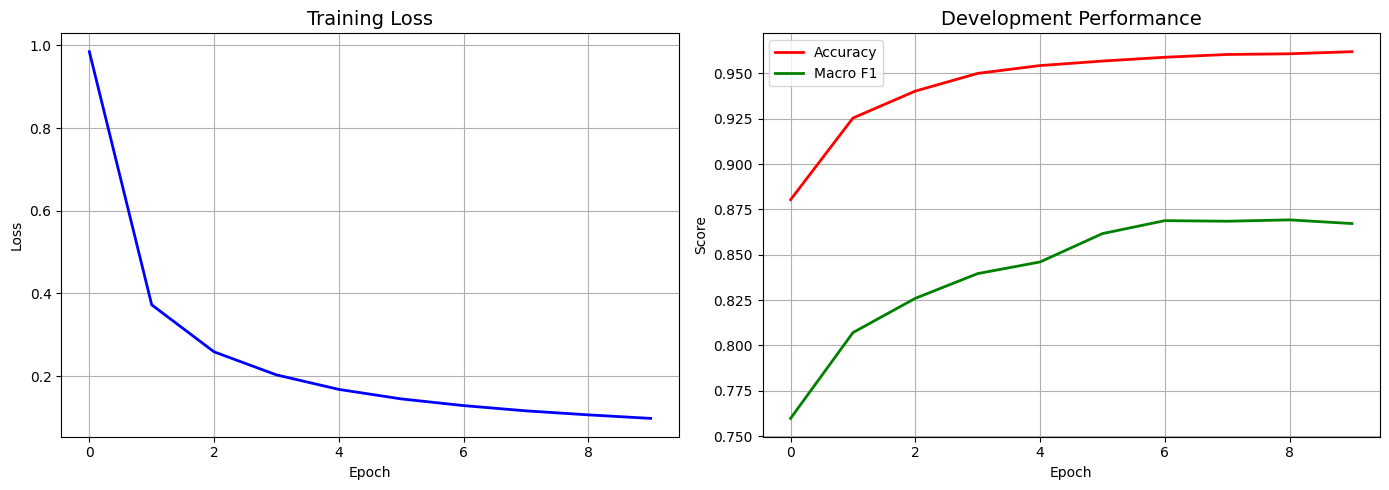

✅ Training curves saved as 'training_curves.png'


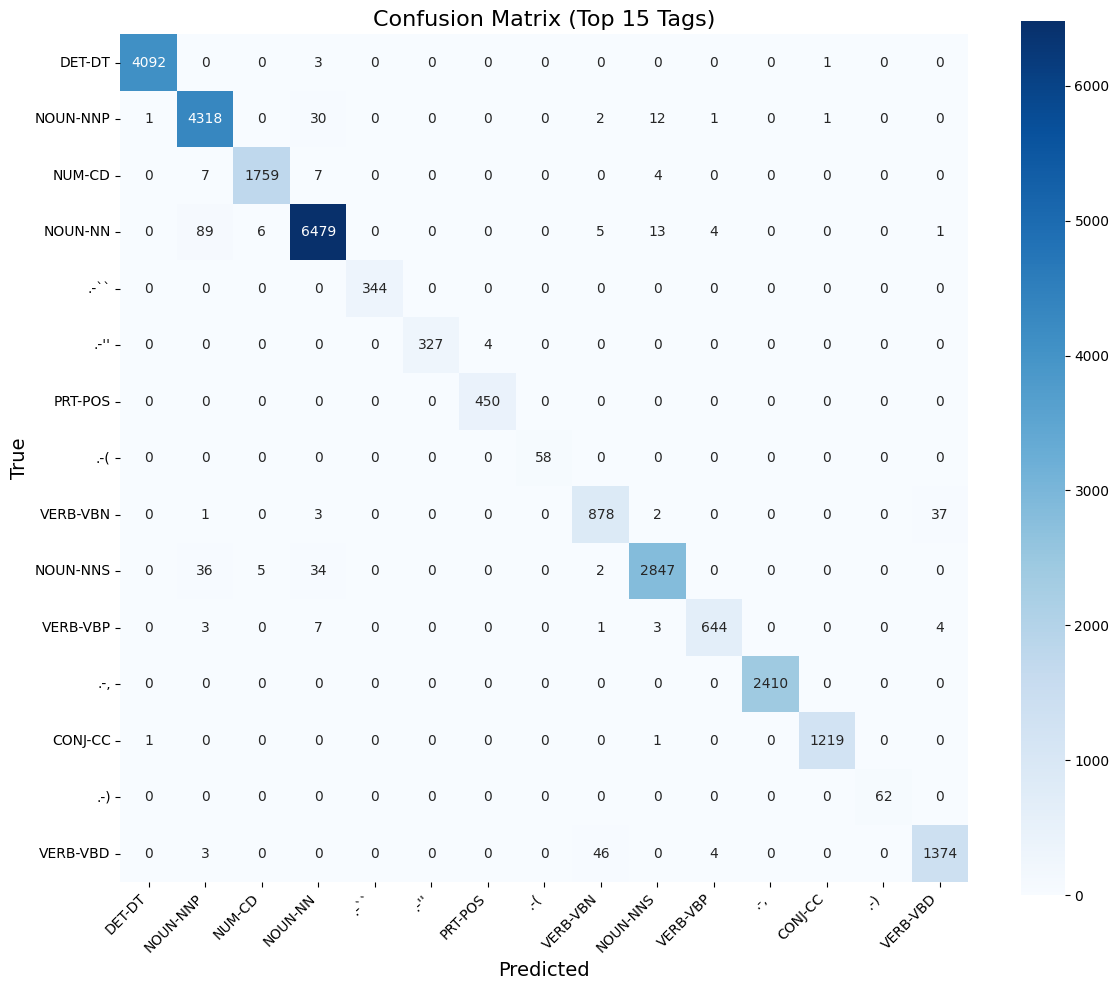

✅ Confusion matrix saved as 'confusion_matrix.png'


In [52]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Select top 15 tags to show
unique_labels = sorted(set(final_metrics['all_labels']))
num_tags_to_show = min(15, len(unique_labels))
selected_labels = unique_labels[:num_tags_to_show]
selected_tag_names = [idx2tag[i] for i in selected_labels]

# Build confusion matrix
cm = confusion_matrix(
    final_metrics['all_labels'], 
    final_metrics['all_preds'],
    labels=selected_labels
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=selected_tag_names,
    yticklabels=selected_tag_names,
    square=True
)
plt.title('Confusion Matrix (Top 15 Tags)', fontsize=16)
plt.xlabel('Predicted', fontsize=14)
plt.ylabel('True', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print("✅ Confusion matrix saved as 'confusion_matrix.png'")

In [54]:
from collections import defaultdict

class BaselineTagger:
    """
    Simple baseline: for each word, choose the most frequent tag
    """
    def __init__(self):
        self.word_to_tag = {}
        self.default_tag = 'NOUN-NN'
    
    def train(self, sentences, tags):
        word_tag_counts = defaultdict(lambda: defaultdict(int))
        
        for sent, tag_seq in zip(sentences, tags):
            for word, tag in zip(sent, tag_seq):
                word_tag_counts[word][tag] += 1
        
        for word, tag_counts in word_tag_counts.items():
            self.word_to_tag[word] = max(tag_counts, key=tag_counts.get)
        
        # Most common tag as default
        all_tags = [tag for tags_seq in tags for tag in tags_seq]
        self.default_tag = Counter(all_tags).most_common(1)[0][0]
    
    def predict(self, sentences):
        predictions = []
        for sent in sentences:
            pred_tags = [self.word_to_tag.get(word, self.default_tag) for word in sent]
            predictions.append(pred_tags)
        return predictions

# Train and evaluate Baseline
print("📊 Training Baseline model...")
baseline = BaselineTagger()
baseline.train(train_sentences, train_tags)

baseline_preds = baseline.predict(dev_sentences)

# Convert to numbers for comparison
baseline_pred_ids = []
baseline_true_ids = []

for pred_seq, true_seq in zip(baseline_preds, dev_tags):
    for pred, true in zip(pred_seq, true_seq):
        baseline_pred_ids.append(tag2idx.get(pred, 0))
        baseline_true_ids.append(tag2idx.get(true, 0))

baseline_acc = accuracy_score(baseline_true_ids, baseline_pred_ids)
baseline_f1 = precision_recall_fscore_support(
    baseline_true_ids, baseline_pred_ids, average='macro', zero_division=0
)[2]

print("\n" + "="*60)
print("📊 COMPARISON: Baseline vs BiLSTM")
print("="*60)
print(f"{'Metric':<20} {'Baseline':<15} {'BiLSTM':<15}")
print("-"*60)
print(f"{'Accuracy':<20} {baseline_acc:<15.4f} {final_metrics['accuracy']:<15.4f}")
print(f"{'Macro F1':<20} {baseline_f1:<15.4f} {final_metrics['macro_f1']:<15.4f}")
print("="*60)

improvement = (final_metrics['accuracy'] - baseline_acc) * 100
print(f"\n📈 Accuracy Improvement: {improvement:.2f}%")

📊 Training Baseline model...

📊 COMPARISON: Baseline vs BiLSTM
Metric               Baseline        BiLSTM         
------------------------------------------------------------
Accuracy             0.9141          0.9669         
Macro F1             0.8050          0.8815         

📈 Accuracy Improvement: 5.27%


In [55]:
# Save the model
torch.save({
    'model_state_dict': model.state_dict(),
    'word2idx': word2idx,
    'tag2idx': tag2idx,
    'max_len': max_len,
    'vocab_size': vocab_size,
    'tag_size': tag_size,
    'embedding_dim': 100,
    'hidden_dim': 128,
    'num_layers': 2,
}, 'pos_tagger_final.pt')

print("✅ Model saved as 'pos_tagger_final.pt'")

# Save results summary
with open('results_summary.txt', 'w', encoding='utf-8') as f:
    f.write("="*60 + "\n")
    f.write("POS TAGGING PROJECT - FINAL RESULTS\n")
    f.write("="*60 + "\n\n")
    
    f.write("DATASET STATISTICS:\n")
    f.write(f"  Train sentences: {len(train_sentences):,}\n")
    f.write(f"  Dev sentences: {len(dev_sentences):,}\n")
    f.write(f"  Vocabulary size: {len(word2idx):,}\n")
    f.write(f"  Number of tags: {len(tag2idx)}\n")
    f.write(f"  Max sentence length: {max_len}\n\n")
    
    f.write("MODEL PERFORMANCE (Dev Set):\n")
    f.write(f"  BiLSTM Accuracy: {final_metrics['accuracy']:.4f}\n")
    f.write(f"  BiLSTM Macro F1: {final_metrics['macro_f1']:.4f}\n\n")
    
    f.write("BASELINE PERFORMANCE (Dev Set):\n")
    f.write(f"  Baseline Accuracy: {baseline_acc:.4f}\n")
    f.write(f"  Baseline Macro F1: {baseline_f1:.4f}\n\n")
    
    f.write("IMPROVEMENT:\n")
    f.write(f"  Accuracy Improvement: {(final_metrics['accuracy'] - baseline_acc)*100:.2f}%\n")
    f.write(f"  Macro F1 Improvement: {(final_metrics['macro_f1'] - baseline_f1)*100:.2f}%\n")

print("✅ Results saved as 'results_summary.txt'")

print("\n" + "="*60)
print("🎉 PROJECT COMPLETED SUCCESSFULLY!")
print("="*60)
print("\n📁 Generated files:")
print("  - pos_tagger_final.pt (model)")
print("  - best_model.pt (best model weights)")
print("  - training_curves.png (plots)")
print("  - confusion_matrix.png (confusion matrix)")
print("  - tag_distribution.png (tag distribution)")
print("  - results_summary.txt (results summary)")



✅ Model saved as 'pos_tagger_final.pt'
✅ Results saved as 'results_summary.txt'

🎉 PROJECT COMPLETED SUCCESSFULLY!

📁 Generated files:
  - pos_tagger_final.pt (model)
  - best_model.pt (best model weights)
  - training_curves.png (plots)
  - confusion_matrix.png (confusion matrix)
  - tag_distribution.png (tag distribution)
  - results_summary.txt (results summary)
